This is an experimental notebook to lay out how the forward modelling approach should work in nirspectroperf. It pre-dates the template that will be made and thus is strictly for experimentation.

In [1]:
from pathlib import Path

import numpy as np
from matplotlib import pyplot as plt

from astropy import units as u
from astropy.coordinates import SkyCoord, SpectralCoord
from astropy import visualization as aviz
aviz.quantity_support()

from jwst import datamodels

import nirspectroperf

from jax import numpy as jnp
import jaxon

from tqdm.auto import tqdm

# Data Loading and Prep

In [2]:
n6791fits = list(Path('../ngc6791_cals').glob('*.fits'))

dm0 = datamodels.open(n6791fits[0])

slit = dm0.slits[49]
scoord = SkyCoord(slit.source_ra, slit.source_dec, unit='deg')

assert slit.source_name == '2609_21'

In [3]:
apogee_id = '2M19210086+3745339'
apogee_vhelio_avg = -45.42058
apogee_vunc = 0.1100559
apogee_teff = 4416.742
apogee_logg = 2.269546
apogee_m_h = 0.34755

apogee_feh = np.log10(apogee_m_h)

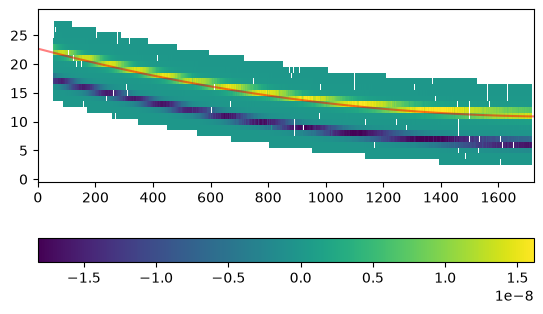

In [4]:
pos0 = SkyCoord(slit.source_ra*u.deg, slit.source_dec*u.deg)
specc = SpectralCoord(np.linspace(0.7, 1.4, 1000)*u.micron)
xtrace, ytrace = slit.meta.wcs.world_to_pixel(pos0, specc)

plt.plot(xtrace, ytrace, 'r-', alpha=.5)

sc,_ = aviz.imshow_norm(slit.data, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                   aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

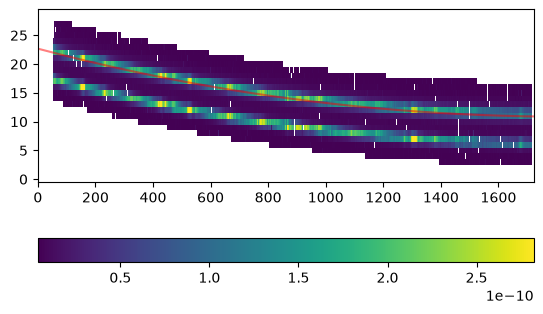

In [5]:
plt.plot(xtrace, ytrace, 'r-', alpha=.5)

sc,_ = aviz.imshow_norm(slit.err, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

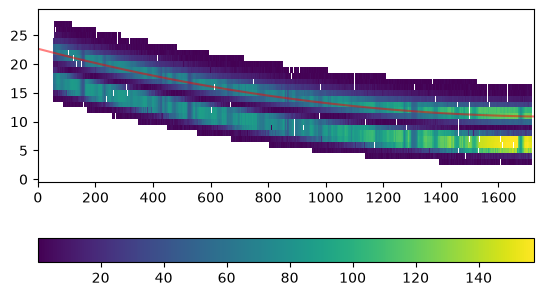

In [6]:
plt.plot(xtrace, ytrace, 'r-', alpha=.5)

sc,_ = aviz.imshow_norm(np.abs(slit.data)/slit.err, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

The model doesn't currently know what to do with negatives, so we just nan them for now

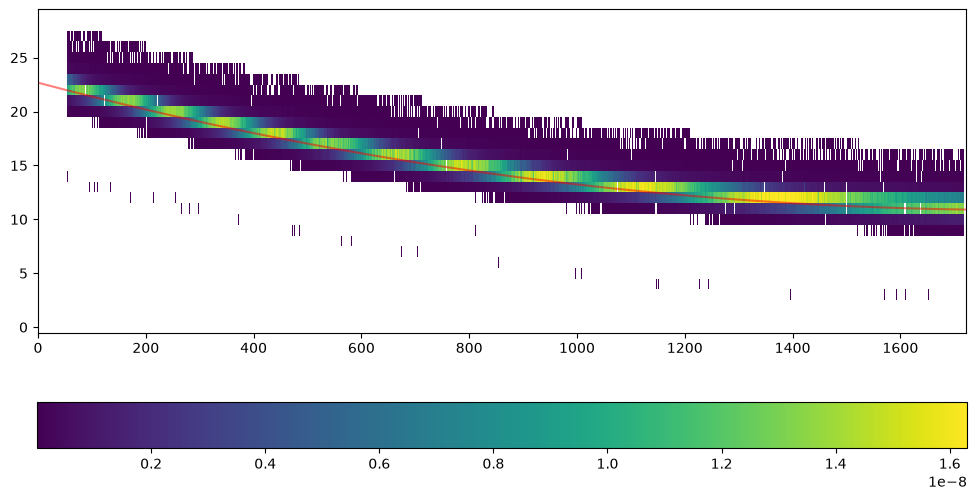

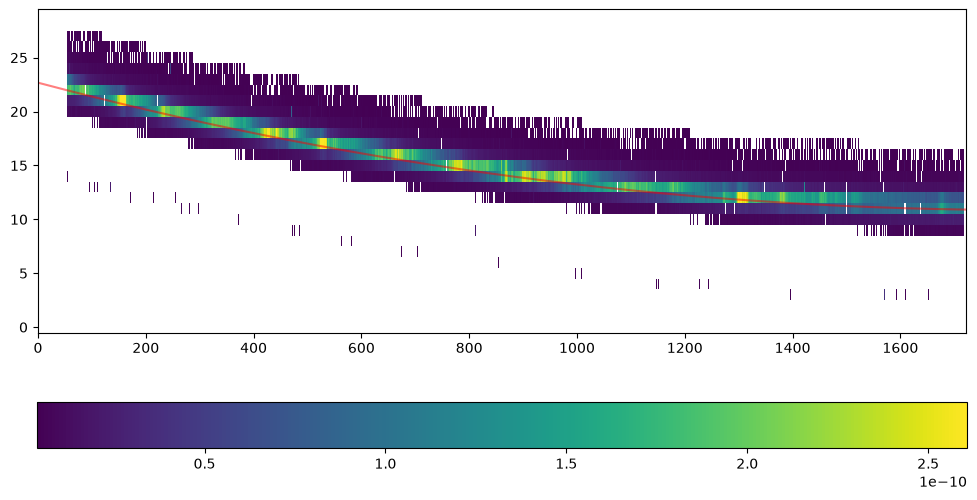

In [7]:
negmsk = slit.data < 0

naneddata = np.copy(slit.data)
naneddata[negmsk] = np.nan
nanederr = np.copy(slit.err)
nanederr[negmsk] = np.nan

fig1 = plt.figure(figsize=(12, 6))
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(naneddata, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

fig2 = plt.figure(figsize=(12, 6))
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(nanederr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

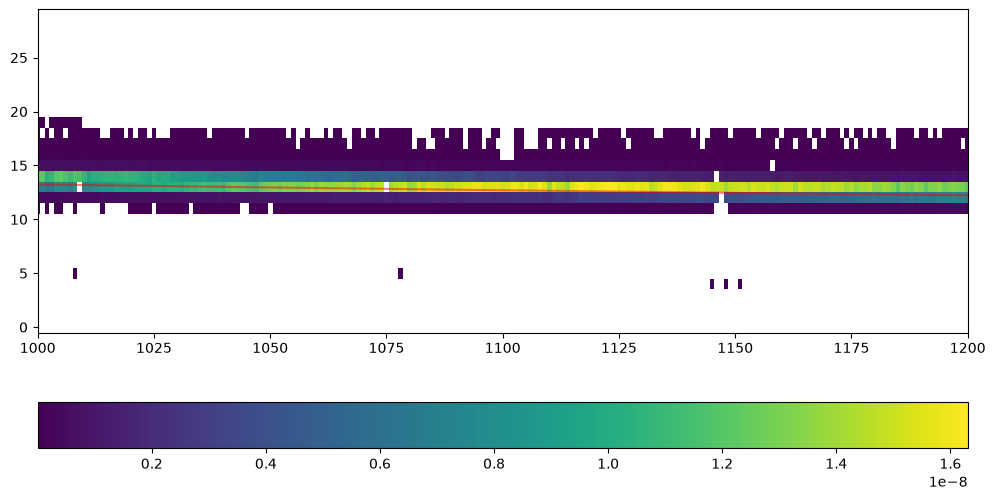

In [8]:
fig1.axes[0].set_xlim(1000, 1200)
fig1.axes[0].set_aspect('auto')
fig1

Set the model parameters to use below for testing

In [9]:
true_params = [1, 0, 0, apogee_vhelio_avg, apogee_teff, apogee_logg, apogee_feh]
true_params

[1, 0, 0, -45.42058, 4416.742, 2.269546, np.float64(-0.45898270715434314)]

Choose a set of model parameters that match one of the direct models but are fairly close to the above

In [10]:
trueish_params = [1, 0, 0, 0, 4400, 2.5, -.5]

# Direct Model

Do some sanity checks with the direct model to comapre below to the accelerated models

/var/home/erik/astro/m31_jwst_2609_vol2/.pixi/envs/gpu/lib/python3.14/site-packages/cupyx/jit/_interface.py:247: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


iterating query, tdelta=3.0

MAST OPD query around UTC: 60136.5904089294
                        MJD: 60136.5904089294

OPD immediately preceding the given datetime:
	URI:	 mast:JWST/product/R2023071203-NRCA3_FP1-1.fits
	Date (MJD):	 60136.5363
	Delta time:	 -0.0542 days

OPD immediately following the given datetime:
	URI:	 mast:JWST/product/R2023071403-NRCA3_FP1-1.fits
	Date (MJD):	 60138.8979
	Delta time:	 2.3075 days
User requested choosing OPD time closest in time to 60136.5904089294, which is R2023071203-NRCA3_FP1-1.fits, delta time -0.054 days
Importing and format-converting OPD from /home/erik/data/stpsf-data/MAST_JWST_WSS_OPDs/R2023071203-NRCA3_FP1-1.fits
Backing out SI WFE and OTE field dependence at the WF sensing field point (NRCA3_FP1)
Sensing inst model using apername NRCA3_FP1
Using sensing field point SI WFE model from file wss_target_phase_fp1.fits


(<Quantity -0.0656 arcsec>, <Quantity 0.06946001 arcsec>)

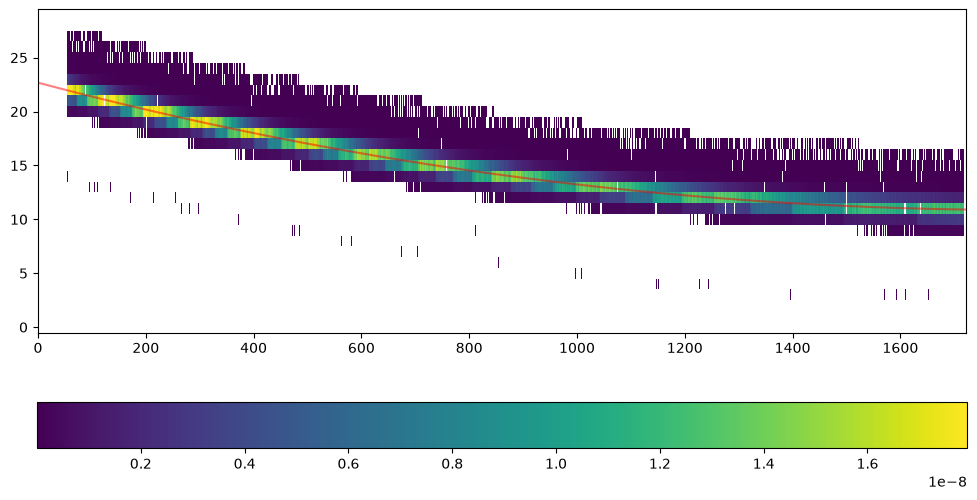

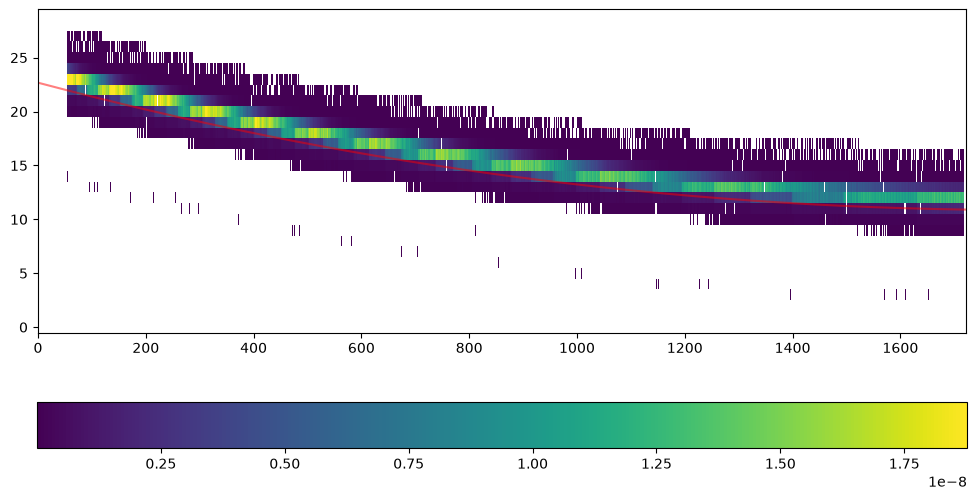

In [11]:
direct_model = nirspectroperf.NIRSpecSlitStarModel.make_from_template(dm0, slit)
direct_model.slit_data_template = naneddata  

trueish_paramst = trueish_params.copy()
trueish_paramst[0] = 1
trueish_paramst[1] = 0.
trueish_paramst[2] = 0.
trueish_paramst[-3:] = [4400, 2.5, -.5]


modarr = direct_model.make_model(trueish_paramst)

trueish_paramst[0] = np.nansum(naneddata) / np.nansum(modarr)

modarr = direct_model.make_model(trueish_paramst)

fig1 = plt.figure(figsize=(12, 6))
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

# compare to a y-offset version

fig2 = plt.figure(figsize=(12, 6))

trueish_paramst[2] = 0.12 # arcsec

trueish_paramst[0] = 1
modarrt = direct_model.make_model(trueish_paramst)

trueish_paramst[0] = np.nansum(naneddata) / np.nansum(modarrt)

modarrt = direct_model.make_model(trueish_paramst)

plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarrt, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

direct_model.x_slit0, direct_model.y_slit0

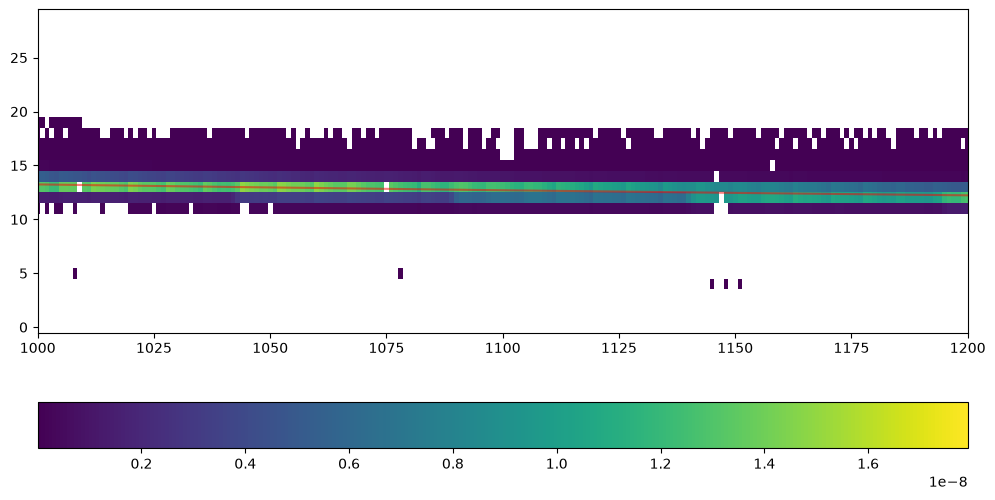

In [12]:
fig1.axes[0].set_xlim(1000, 1200)
fig1.axes[0].set_aspect('auto')
fig1

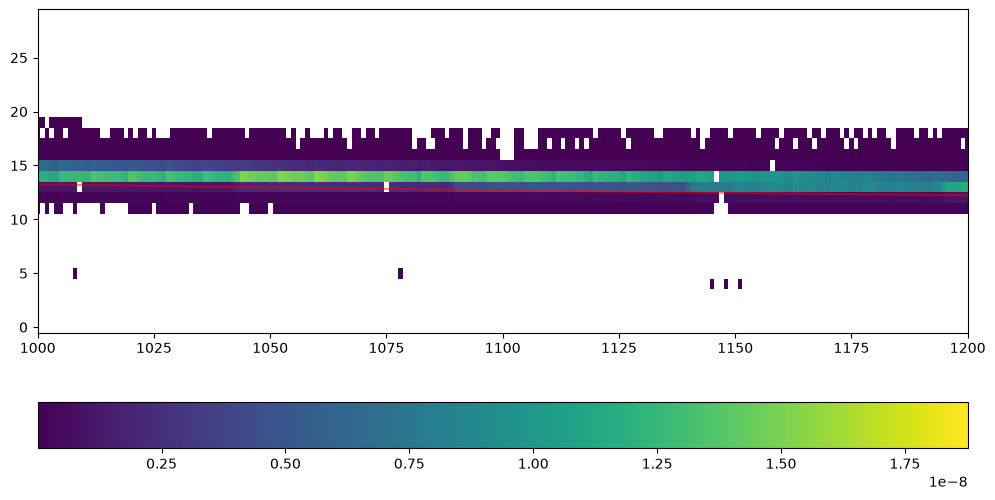

In [13]:
fig2.axes[0].set_xlim(1000, 1200)
fig2.axes[0].set_aspect('auto')
fig2

Take a look at the PSFs used for the above just to make sure it makes sense

In [14]:
trueish_paramst

[np.float32(1.6839592e-37), 0.0, 0.12, 0, 4400, 2.5, -0.5]

(np.float64(-0.06560000181198121), np.float64(0.18946001052856445))

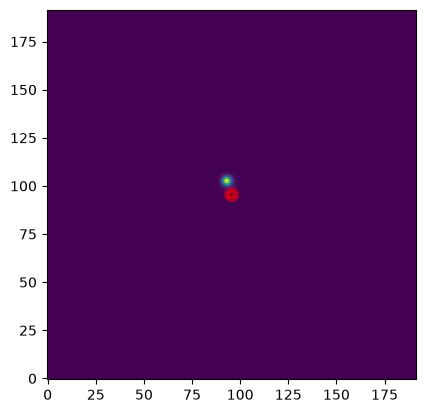

In [15]:
xo = direct_model.x_slit0.to_value(u.arcsec) + trueish_paramst[1]
yo = direct_model.y_slit0.to_value(u.arcsec) + trueish_paramst[2]

plt.imshow(direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)[-1].T, origin='lower')
plt.contour(direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)[-1].T, colors='r', alpha=.5, lw=1)

xo,yo

-23.246213063086774 24.503786936913226 -25.691005737762733 22.058994262237267 0.6287869369132264 -1.816005737762734
-23.875 23.875 -23.875 23.875 0.0 0.0


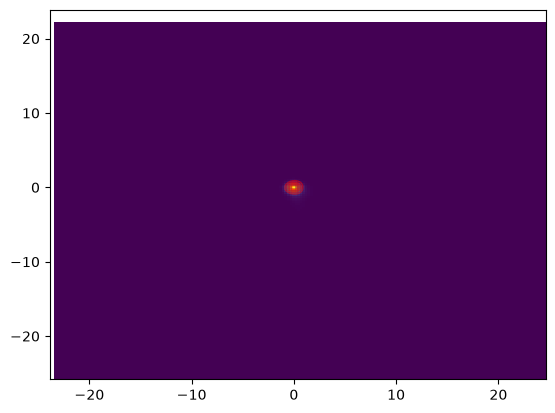

In [16]:
x,y,f = direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.pcolor(x, y, f)

x,y,f = direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='r', alpha=.5, lw=1)

-23.246213063086774 24.503786936913226 -25.691005737762733 22.058994262237267 0.6287869369132264 -1.816005737762734
-23.246213063086774 24.503786936913226 -24.54078576298514 23.20921423701486 0.6287869369132264 -0.6657857629851396
-23.875 23.875 -23.875 23.875 0.0 0.0


(-2.5, 2.5)

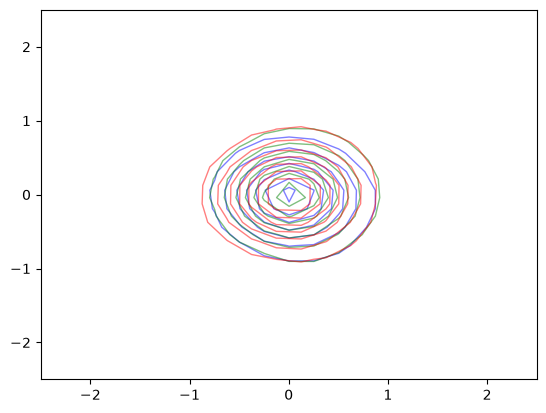

In [17]:
x,y,f = direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='b', alpha=.5, lw=1)

x,y,f = direct_model.psf_model.evaluate_psf(direct_model.x_slit0.to_value(u.arcsec) , direct_model.y_slit0.to_value(u.arcsec) , 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='g', alpha=.5, lw=1)

x,y,f = direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)
print(x.min(), x.max(), y.min(), y.max(), x.mean(), y.mean())
plt.contour(x, y, f, colors='r', alpha=.5, lw=1)

plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)

(np.float64(-2.515147747652903),
 np.float64(7.264022951050931),
 (np.float64(-0.656000018119812), np.float64(0.5628696109937584)))

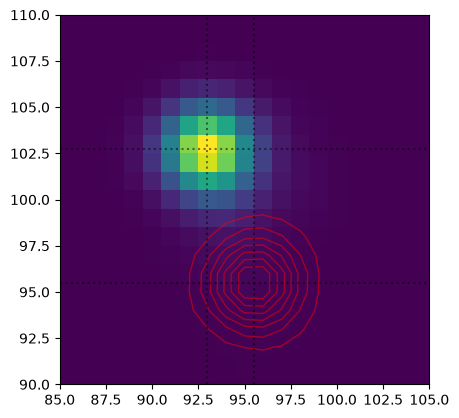

In [18]:
plt.imshow(direct_model.psf_model.evaluate_psf(xo, yo, 1.17*u.micron)[-1].T)
plt.contour(direct_model.psf_model.evaluate_psf(0, 0, 1.17*u.micron)[-1].T, colors='r', alpha=.5, lw=1)
plt.axvline(95.5, c='k', ls=':', alpha=.5)
plt.axhline(95.5, c='k', ls=':', alpha=.5)

pxoffx = (direct_model.psf_model.detector_pixelscale*xo*u.arcsec).to_value(u.pixel)*direct_model.psf_model.oversampling
pxoffy = (direct_model.psf_model.detector_pixelscale*yo*u.arcsec).to_value(u.pixel)*direct_model.psf_model.oversampling
                                                                               
plt.axvline(95.5 + pxoffx, c='k', ls=':', alpha=.5)
plt.axhline(95.5 + pxoffy, c='k', ls=':', alpha=.5)
plt.xlim(85, 105)
plt.ylim(90, 110)

pxoffx, pxoffy, direct_model.slit_offsets_frac(xo, yo)

# Model loading and prep

In [ ]:
spec_model_path = Path("phoenix_estimator_2026-10-27T14-00-35_model.hdf5")
psf_model_path = Path("psf_training_fiducial.model")

assert spec_model_path.is_file(), 'missing spec model'
assert psf_model_path.is_file(), 'missing psf model'

spec_model = jaxon.load(spec_model_path, allow_dill=True)
psf_model = jaxon.load(psf_model_path, allow_dill=True)

# adapters needed for NIRSpecPSFINREmulator format changing since the original model was made
if psf_model.oversampled_pixelscale.unit.is_equivalent(u.arcsec/u.pixel):
    psf_model.oversampled_pixelscale = 1/psf_model.oversampled_pixelscale


cached_psf = np.load('psf_cache.npz', allow_pickle=True)

In [20]:
chebw2p = nirspectroperf.ChebyshevW2P.derive_from_wcs(slit.meta.wcs, (2, 2, 7), slit.data.shape)

In [21]:
slit_model = nirspectroperf.NIRSpecSlitStarModel(spec_model, psf_model, chebw2p, slit)
slit_model.slit_data_template = naneddata  # Set the slit data template to the NaN-ed data - we do it here because the slit info is needed at initialization

slit_model.param_names

['F0', 'x_slit_offset', 'y_slit_offset', 'v', 'teff', 'logg', 'feh']

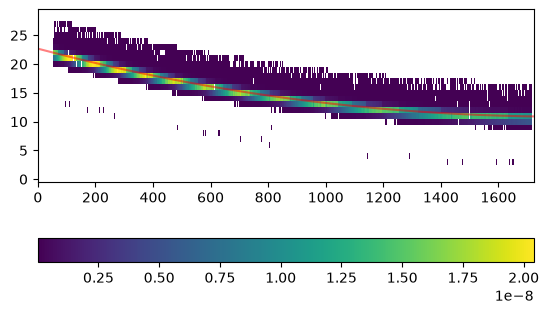

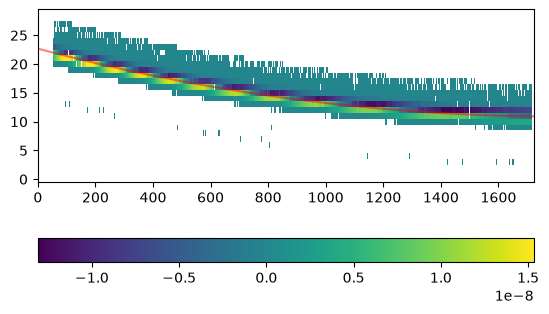

In [22]:
trueish_params = [1, 0, 0, apogee_vhelio_avg, apogee_teff, apogee_logg, apogee_feh]
trueish_params[-3:] = [4400, 2.5, -.5]  # for comparison with above

modarr = slit_model.make_model(trueish_params)

trueish_params[0] = np.nansum(naneddata) / np.nansum(modarr)


modarr = slit_model.make_model(trueish_params)

plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

fig1 = plt.gcf()
fig2 = plt.figure()
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr-naneddata, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

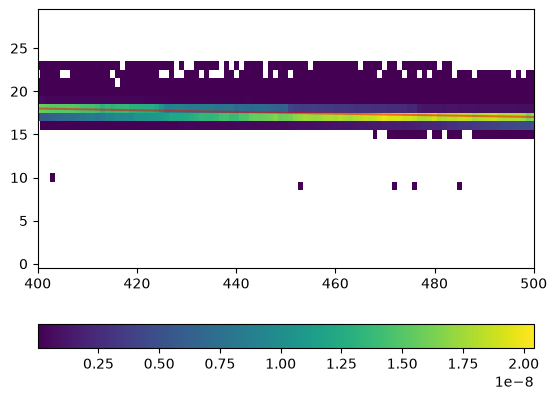

In [23]:
fig1.axes[0].set_xlim(400, 500)
fig1.axes[0].set_aspect('auto')
fig1

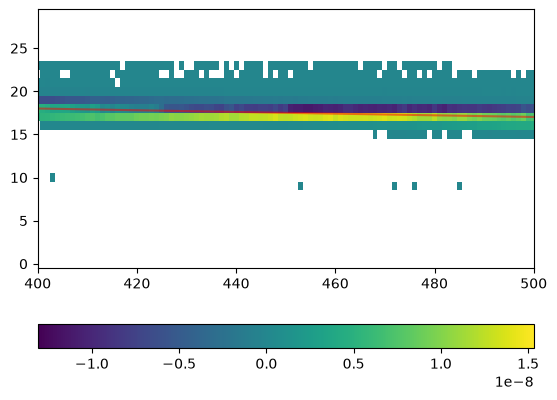

In [24]:
fig2.axes[0].set_xlim(400, 500)
fig2.axes[0].set_aspect('auto')
fig2

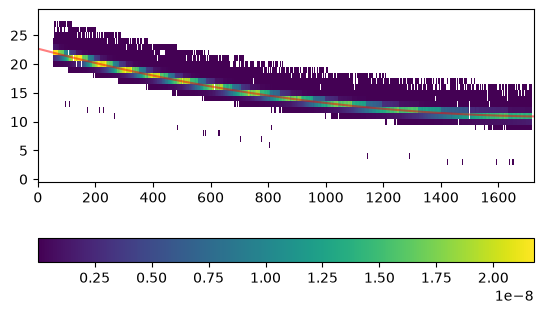

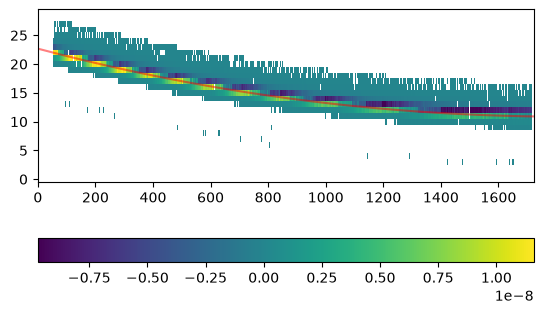

In [25]:
trueish_params = [1, 0, 0.05, apogee_vhelio_avg, apogee_teff, apogee_logg, apogee_feh]
trueish_params[-3:] = [4400, 2.5, -.5]  # for comparison with above

modarr = slit_model.make_model(trueish_params)

trueish_params[0] = np.nansum(naneddata) / np.nansum(modarr)


modarr = slit_model.make_model(trueish_params)

plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

fig1 = plt.gcf()
fig2 = plt.figure()
plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr-naneddata, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect=20, origin='lower', interpolation='nearest')
plt.colorbar(sc, ax=plt.gca(), orientation='horizontal')

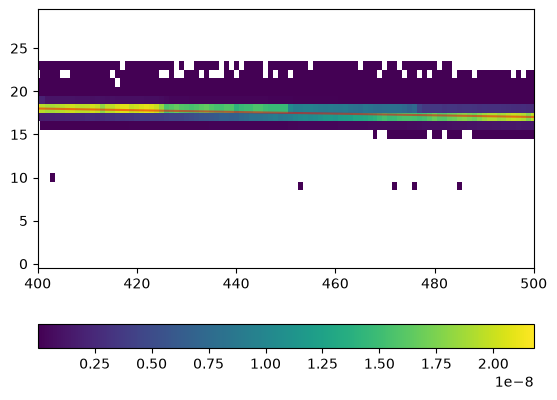

In [26]:
fig1.axes[0].set_xlim(400, 500)
fig1.axes[0].set_aspect('auto')
fig1

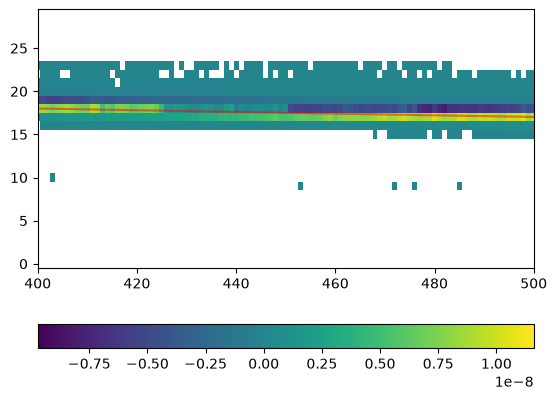

In [27]:
fig2.axes[0].set_xlim(400, 500)
fig2.axes[0].set_aspect('auto')
fig2

Things look rather different... check the parts, what might be different. Start with spectrum

(0.7, 1.0)

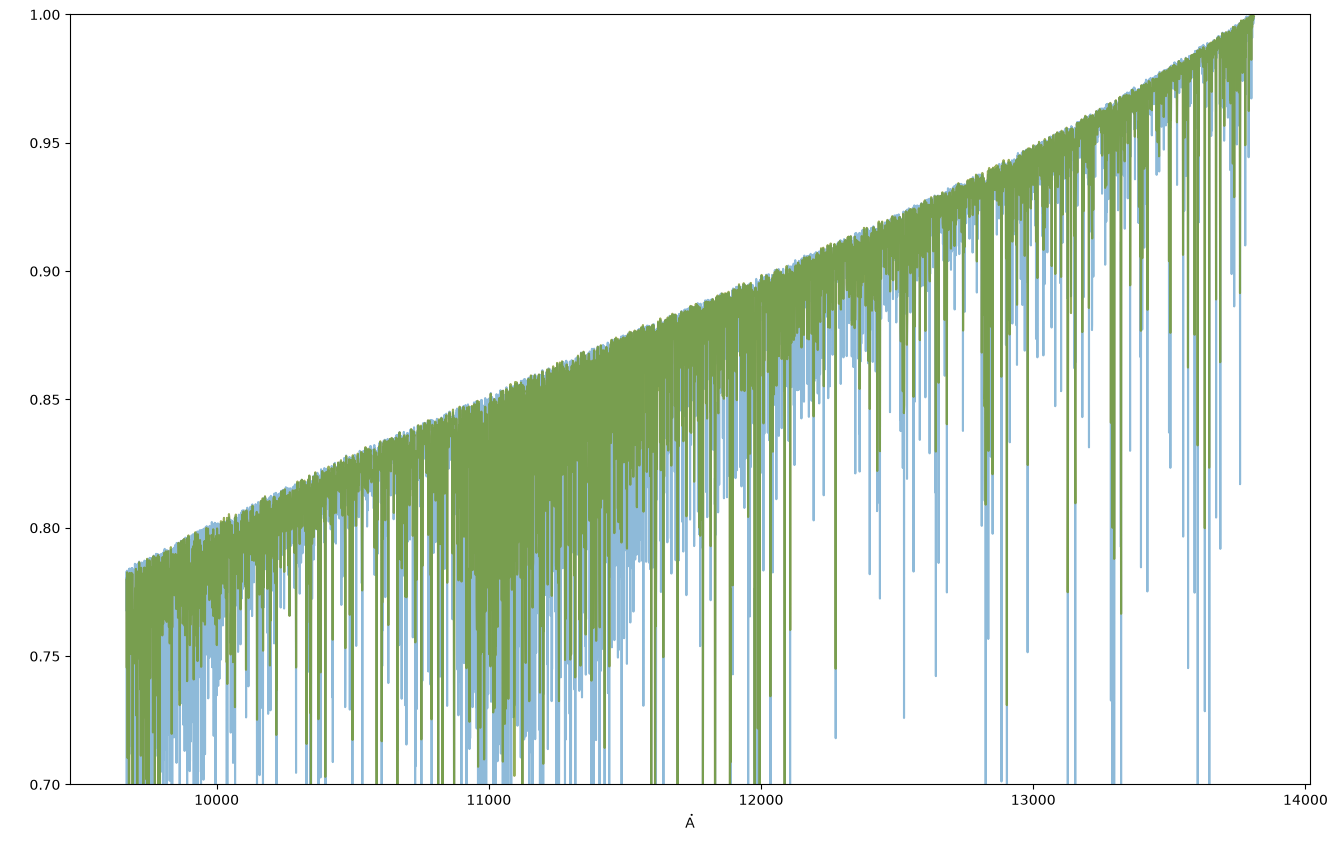

In [28]:
fig = plt.figure(figsize=(16, 10))
s = slit_model.spec_model.make_spectrum(*trueish_params[-3:])
plt.plot(s.wavelength, s.flux/np.max(s.flux), alpha=.5)

s2 = direct_model.spec_model.make_spectrum(*trueish_params[-3:])
plt.plot(s2.wavelength, s2.flux/np.max(s2.flux), alpha=.5)

s3 = direct_model.spec_model.resample_spectrum_to_wave(s2.spectral_axis, *trueish_params[-3:])
plt.plot(s3.wavelength, s3.flux/np.max(s3.flux), alpha=.5)

plt.ylim(.7, 1)

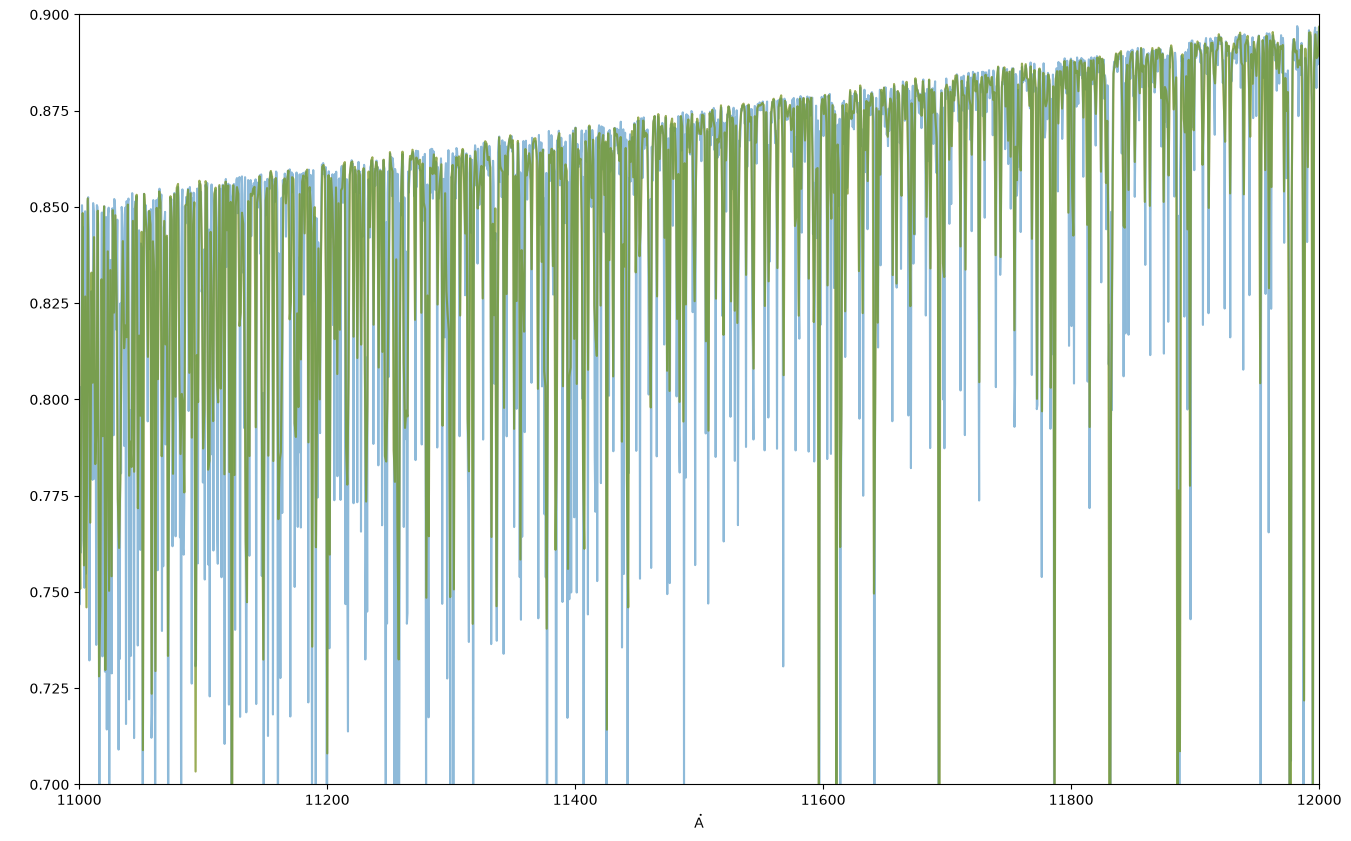

In [29]:
fig.axes[0].set_ylim(.7, .9)
fig.axes[0].set_xlim(11000, 12000)
fig

Well huh, why are they so different?? Check the PSF as well to be sure.

/tmp/ipykernel_77071/2222389798.py:14: UserWarning: Legend does not support handles for QuadContourSet instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  plt.legend(loc=0)
/tmp/ipykernel_77071/2222389798.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc=0)


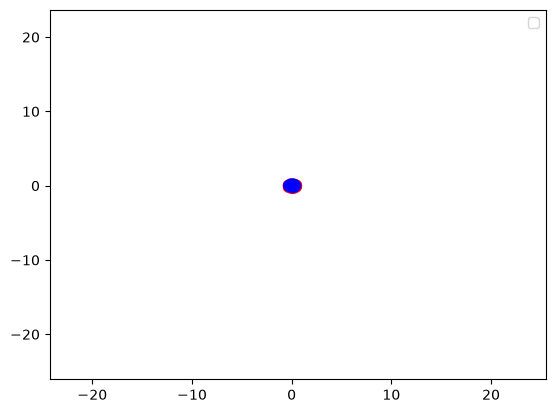

(-2.5, 2.5)

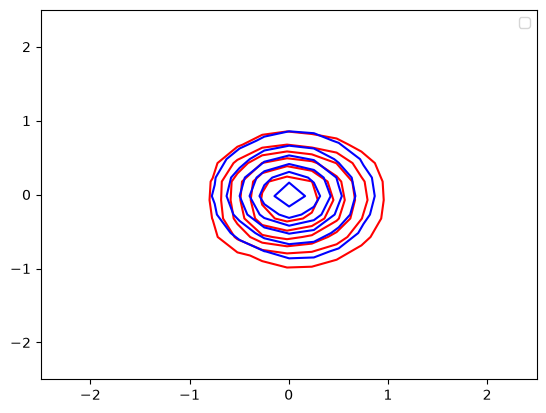

In [30]:
xo1 = slit_model._x_slit0_asec + trueish_params[1]
yo1 = slit_model._y_slit0_asec + trueish_params[2]
psf1 = slit_model.psf_model.evaluate_psf(xo1, yo1, s.spectral_axis.mean())

xo2 = direct_model._x_slit0_asec + trueish_params[1]
yo2 = direct_model._y_slit0_asec + trueish_params[2]
psf2 = direct_model.psf_model.evaluate_psf(xo2, yo2, s.spectral_axis.mean())

assert xo1 == xo2
assert yo1 == yo2

plt.contour(*psf1, colors='r', label='inr')
plt.contour(*psf2, colors='b', label='direct')
plt.legend(loc=0)
display(plt.gcf())

plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)

Ok, they match (more or less)!

# Compare the slit model to the matching spectrum

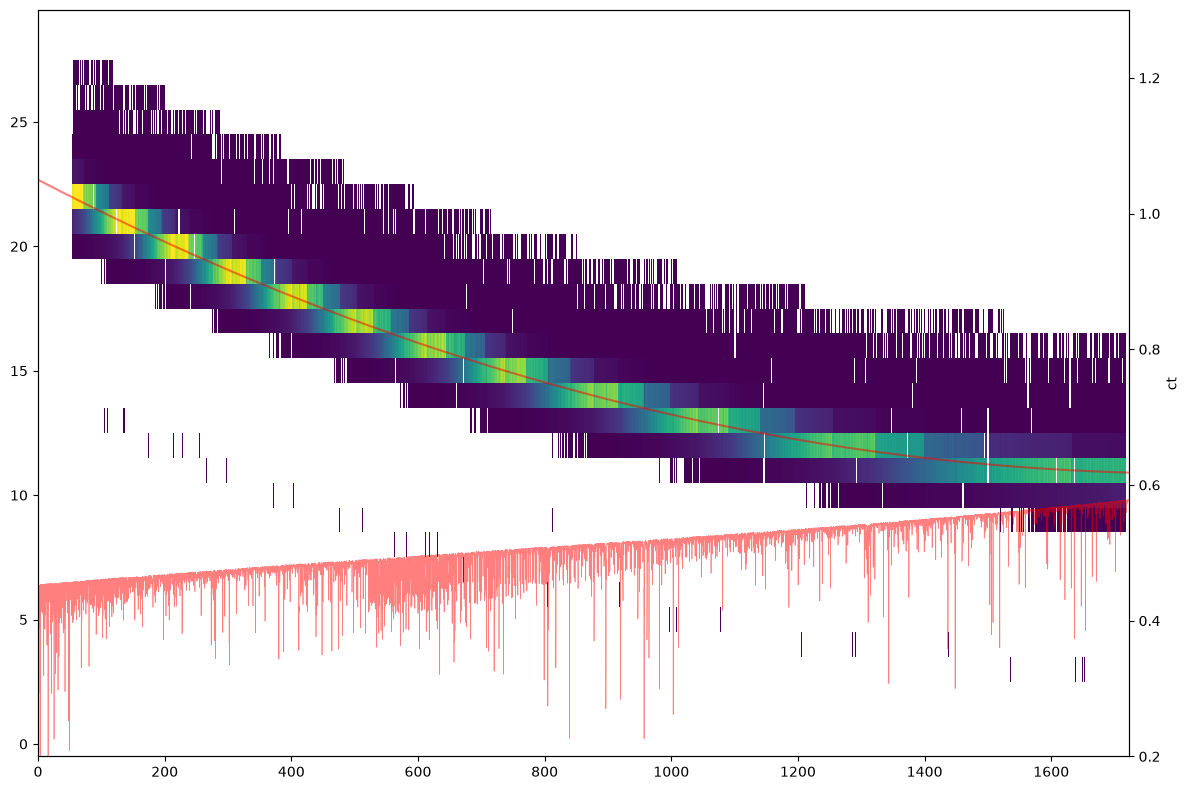

(0.4, 0.8)

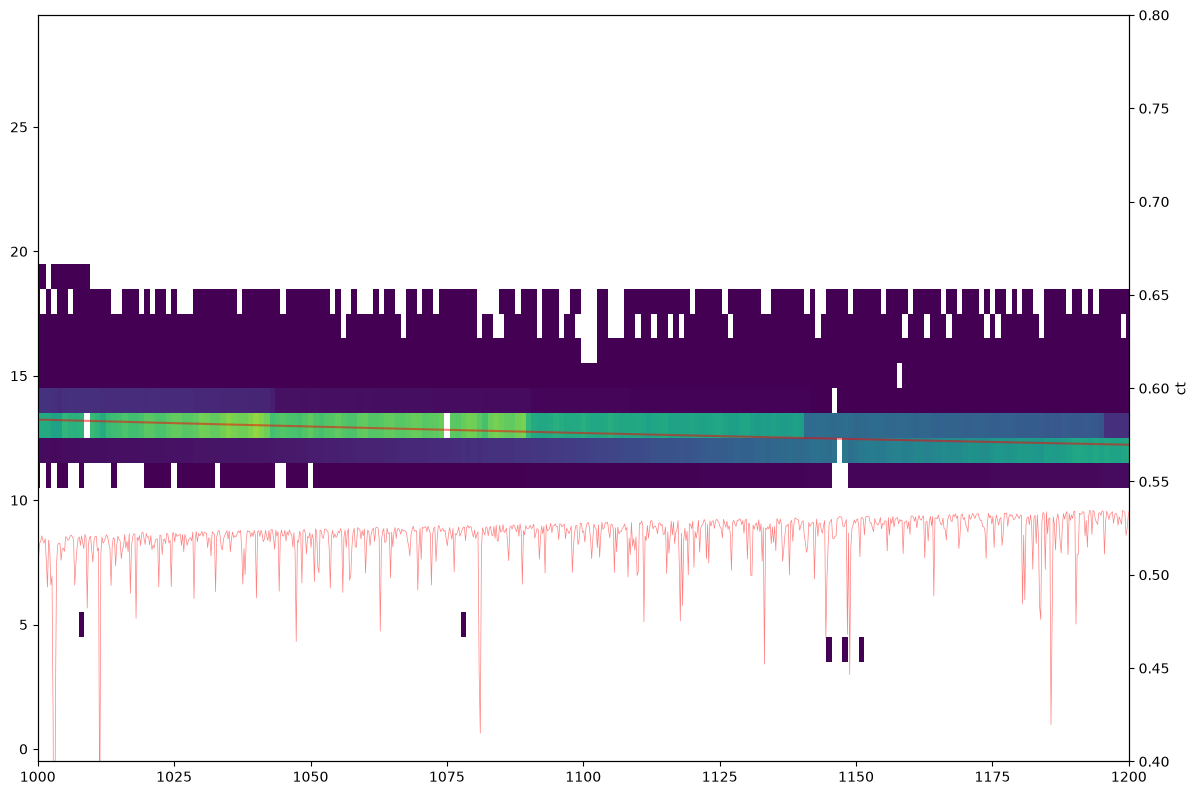

In [31]:
trueish_params = [1, 0, 0.05, apogee_vhelio_avg, apogee_teff, apogee_logg, apogee_feh]
trueish_params[-3:] = [4400, 2.5, -.5]  # for comparison with above

modarr = slit_model.make_model(trueish_params)

trueish_params[0] = np.nansum(naneddata) / np.nansum(modarr)

modarr = slit_model.make_model(trueish_params)

wv = direct_model.w2p.wcs.pixel_to_world_values(xtrace, ytrace)
iworld = 500
ra0 = wv[0][iworld]
dec0 = wv[1][iworld]
sxs, sys = direct_model.w2p.wcs.world_to_pixel_values(ra0, dec0, s.spectral_axis.value)

s = slit_model.spec_model.make_spectrum(*trueish_params[-3:])


fig = plt.figure(figsize=(12, 8))

plt.plot(xtrace, ytrace, 'r-', alpha=.5)
sc,_ = aviz.imshow_norm(modarr, stretch=aviz.LinearStretch(), interval=aviz.PercentileInterval(99.5), 
                                                  aspect='auto', origin='lower', interpolation='nearest')

plt.twinx()
plt.plot(sxs, s.flux,c='r', alpha=.5, lw=.5)
plt.ylim(0.2, 1.3)

fig.tight_layout()

display(fig)

plt.xlim(1000, 1200)
plt.ylim(0.4, .8)